# Auswertung der Ergebnisse Modell und Schema Vergleich

Getestet wurden 4 Open-Source Modelle, jeweils mit JSON-Schema an und aus sowie mit einem ganz kurzen Prompt (Miniprompt) und einem Regelprompt (deutlich ausführlicher und strukturierter).

Modelle:
* Llama3.1-8B-instruct
* NuExtract3-4B
* Qwen2.5-7B-instruct
* Qwen2.5-coder-14B-instruct

In [32]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('ergebnisse_modell_schema.csv', sep=';', decimal=',')

In [33]:
df.head(10)

,Run_ID,Modell,Artikel_ID,Strategie,JSON_Schema,Parsbar_1_0,Schema_OK_1_0,Laufzeit_in_s,Total_tokens,Confusion_Matrix,Verpackungsebene_korrekt?_1_0,Artikelnummer_korrekt?_1_0,Labelinhalte_gefunden_%
0,1,Llama-3.1-8b-instruct,20323-000,Minimalprompt,Aus,1,0,4.654,1409,FN,0,1,0.0
1,2,Llama-3.1-8b-instruct,20323-000,Minimalprompt,An,1,1,12.072,1560,TP,1,1,1.0
2,3,Llama-3.1-8b-instruct,20323-000,Regelprompt,Aus,0,0,109.054,3485,FN,0,0,0.0
3,4,Llama-3.1-8b-instruct,20323-000,Regelprompt,An,1,1,11.366,2398,TP,1,1,1.0
4,5,Llama-3.1-8b-instruct,40402-405,Minimalprompt,Aus,0,0,12.604,769,FN,0,1,0.5
5,6,Llama-3.1-8b-instruct,40402-405,Minimalprompt,An,1,1,6.384,812,TP,1,1,1.0
6,7,Llama-3.1-8b-instruct,40402-405,Regelprompt,Aus,1,0,62.156,2542,FN,0,0,0.0
7,8,Llama-3.1-8b-instruct,40402-405,Regelprompt,An,1,1,6.962,1677,TP,1,1,1.0
8,9,Llama-3.1-8b-instruct,40135-014,Minimalprompt,Aus,1,0,10.745,643,FN,0,1,1.0
9,10,Llama-3.1-8b-instruct,40135-014,Minimalprompt,An,1,1,5.632,671,FP,1,1,1.0


In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 160 entries, 0 to 159
Data columns (total 13 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Run_ID                         160 non-null    int64  
 1   Modell                         160 non-null    object 
 2   Artikel_ID                     160 non-null    object 
 3   Strategie                      160 non-null    object 
 4   JSON_Schema                    160 non-null    object 
 5   Parsbar_1_0                    160 non-null    int64  
 6   Schema_OK_1_0                  160 non-null    int64  
 7   Laufzeit_in_s                  160 non-null    float64
 8   Total_tokens                   160 non-null    int64  
 9   Confusion_Matrix               160 non-null    object 
 10  Verpackungsebene_korrekt?_1_0  160 non-null    int64  
 11  Artikelnummer_korrekt?_1_0     160 non-null    int64  
 12  Labelinhalte_gefunden_%        160 non-null    flo

In [35]:
# One-Hot-Encoding
# df_encoded = pd.get_dummies(df, columns=['Modell', 'Artikel_ID', 'Strategie', 'JSON_Schema', 'Confusion_Matrix'], dtype=int)

# df_encoded.sample(5)

## Formstabilität

### Durchschnittliche Formstabilität über alle Modelle hinweg

--- Formstabilität (%) ---
JSON_Schema      An   Aus
Strategie                
Minimalprompt  90.0  30.0
Regelprompt    97.5  75.0


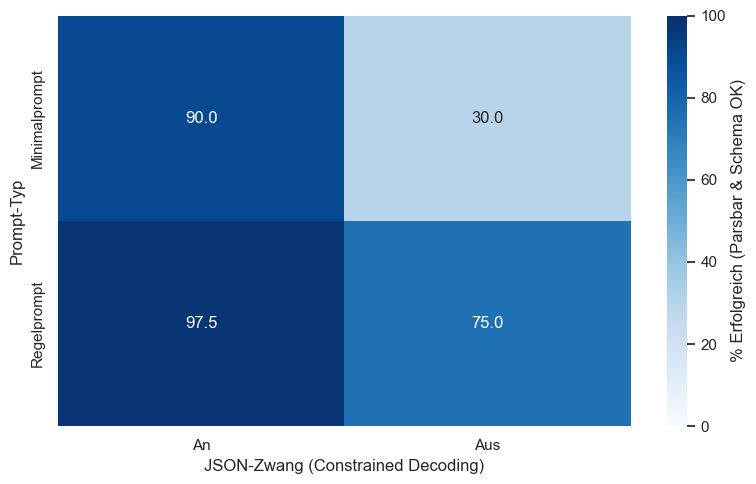

In [36]:
# ==========================================
# 1. Daten aggregieren (Pivot-Tabellen)
# ==========================================
# Wir berechnen den Durchschnitt (mean) und nehmen ihn mal 100 für die Prozent-Darstellung

df['formstabil_gesamt'] = (df['Parsbar_1_0'] == 1) & (df['Schema_OK_1_0'] == 1) 

# Pivot-Tabelle für Parsbarkeit
pivot_form = df.pivot_table(
    index='Strategie', 
    columns='JSON_Schema', 
    values='formstabil_gesamt', 
    aggfunc='mean'
) * 100


# Zeige die Tabellen in der Konsole an
print("--- Formstabilität (%) ---")
print(pivot_form)

# ==========================================
# 2. Visualisierung mit Seaborn (Heatmaps)
# ==========================================

plt.figure(figsize=(8, 5))

sns.heatmap(
    pivot_form, 
    annot=True,          
    fmt=".1f",           
    cmap="Blues",        
    vmin=0, vmax=100,    
    cbar_kws={'label': '% Erfolgreich (Parsbar & Schema OK)'}
)

# plt.title('Strikte Formstabilität nach Setup', fontsize=14, pad=15)
plt.xlabel('JSON-Zwang (Constrained Decoding)', fontsize=12)
plt.ylabel('Prompt-Typ', fontsize=12)

plt.tight_layout()

# Als PDF speichern
plt.savefig("mein_plot.pdf", format="pdf", bbox_inches="tight")

plt.show()

### Formstabilität pro Modell

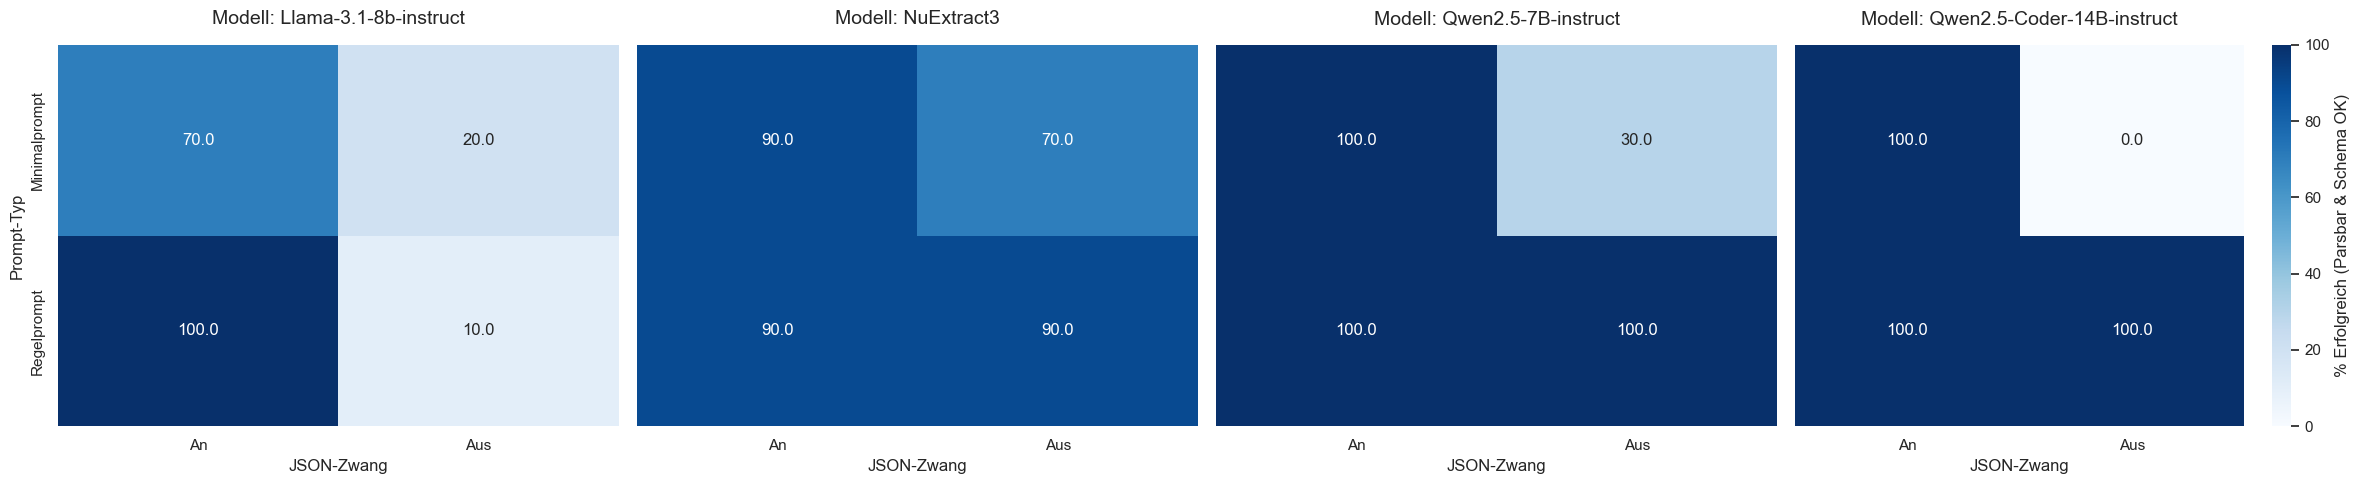

In [37]:
# ==========================================
# 3. Automatische Subplots pro Modell
# ==========================================

modelle = df['Modell'].unique()
anzahl_modelle = len(modelle)

# Erstelle dynamisch nebeneinanderliegende Diagramme
# sharey=True sorgt dafür, dass die Y-Achse (Prompt-Typ) nur links beim ersten Plot steht
fig, axes = plt.subplots(1, anzahl_modelle, figsize=(6 * anzahl_modelle, 5), sharey=True)

# Falls es nur ein Modell gibt, wandle axes in eine Liste um, damit die Schleife nicht abstürzt
if anzahl_modelle == 1:
    axes = [axes]

# Gehe jedes Modell durch, filtere die Daten und zeichne die Heatmap
for i, modell_name in enumerate(modelle):
    
    # 1. Daten nur für das aktuelle Modell filtern
    df_gefiltert = df[df['Modell'] == modell_name]
    
    # 2. Pivot-Tabelle berechnen
    pivot_form = df_gefiltert.pivot_table(
        index='Strategie', 
        columns='JSON_Schema', 
        values='formstabil_gesamt', 
        aggfunc='mean'
    ) * 100
    
    # 3. Heatmap in den entsprechenden Subplot (axes[i]) zeichnen
    sns.heatmap(
        pivot_form, 
        annot=True,          
        fmt=".1f",           
        cmap="Blues",        
        vmin=0, vmax=100,    
        ax=axes[i],
        cbar=(i == anzahl_modelle - 1), # Farbskala nur beim GANZ RECHTEN Plot anzeigen
        cbar_kws={'label': '% Erfolgreich (Parsbar & Schema OK)'} if (i == anzahl_modelle - 1) else None
    )
    
    # Titel und Achsenbeschriftungen setzen
    axes[i].set_title(f'Modell: {modell_name}', fontsize=14, pad=15)
    axes[i].set_xlabel('JSON-Zwang', fontsize=12)
    
    if i == 0:
        axes[i].set_ylabel('Prompt-Typ', fontsize=12)
    else:
        axes[i].set_ylabel('') # Y-Achsen-Label bei den rechten Plots ausblenden

# Layout hübsch machen
plt.tight_layout()
plt.show()

### Qualität

Wie oft wurde das zu prüfende Label korrekt erkennt? 

Dafür wird die Confusion Matrix ausgewertet:
* TP (True Positive): Doku fordert Label, Modell fordert Label (Korrekt erkannt).
* FN (False Negative): Doku fordert Label, Modell sagt nein (Schlimmer Fehler: Label fehlt!).
* FP (False Positive): Doku fordert kein Label, Modell fordert eins (Ressourcenverschwendung).
* TN (True Negative): Doku fordert kein Label, Modell sagt nein (Korrekt ignoriert).

Und es werden Precision und Recall:
* Precision (Genauigkeit): Wenn das Modell sagt, dass ein Label geprüft werden muss, wie oft stimmt das wirklich? 
    * schlechte Precision: Modell ist übervorsichtig oder es halluziniert. Man muss zusätzlich Label überprüfen, die gar nicht gefordert sind.  
* Recall (Trefferquote/Sensitivität): Von allen Labels, die laut den Dokumenten tatsächlich gefordert sind, wie viele hat das Modell gefunden?
    * schlechter Recall: Sehr problematisch, da Vorgaben übersehen werden. Das System sagt, alles okay, obwohl die Überprüfung des Labels erforderlich ist.



Datensätze gesamt: 160
Datensätze nach Bereinigung (nur formstabile): 117



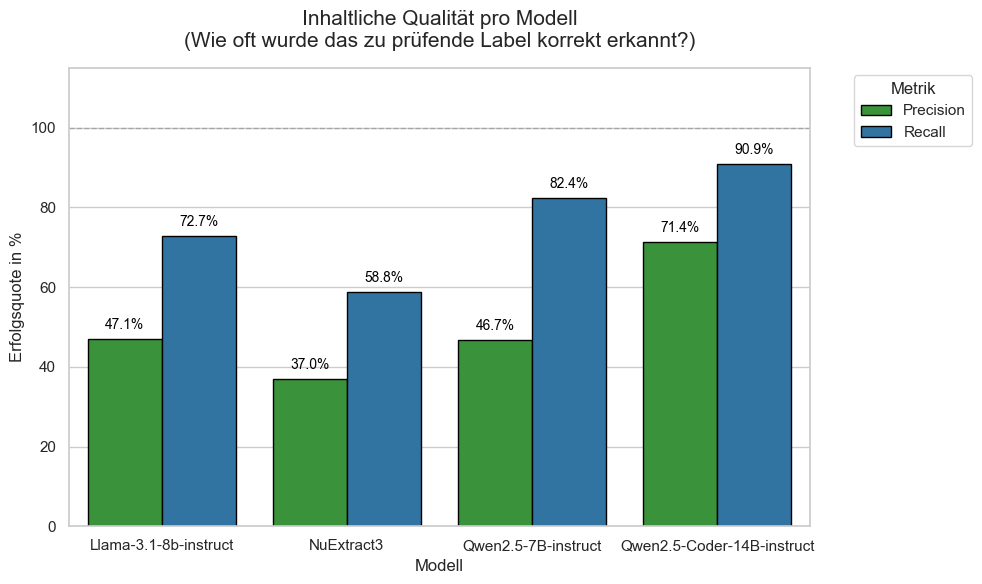

In [38]:
# ==========================================
# 1. Daten bereinigen (Strikter Filter)
# ==========================================
# Wir behalten NUR die Zeilen, bei denen BEIDES 1 ist.
df_bereinigt = df[(df['Parsbar_1_0'] == 1) & (df['Schema_OK_1_0'] == 1)]

print(f"Datensätze gesamt: {len(df)}")
print(f"Datensätze nach Bereinigung (nur formstabile): {len(df_bereinigt)}\n")

# ==========================================
# 2. Metriken pro Modell in einer Schleife berechnen
# ==========================================
alle_modelle = df['Modell'].unique() # Findet alle Modelle, die im Original-Datensatz stehen
ergebnisse = []

for modell in alle_modelle:
    # Nur die bereinigten Daten für das aktuelle Modell filtern
    df_modell = df_bereinigt[df_bereinigt['Modell'] == modell]
    
    # Falls ein Modell nach der Bereinigung gar keine gültigen Antworten mehr hat:
    if len(df_modell) == 0:
        ergebnisse.append({'Modell': modell, 'Precision': 0.0, 'Recall': 0.0})
        continue

    # TP, FP und FN zählen
    werte = df_modell['Confusion_Matrix'].value_counts()
    tp = werte.get('TP', 0)
    fp = werte.get('FP', 0)
    fn = werte.get('FN', 0)

    # Precision berechnen
    precision = (tp / (tp + fp) * 100) if (tp + fp) > 0 else 0.0
    
    # Recall berechnen
    recall = (tp / (tp + fn) * 100) if (tp + fn) > 0 else 0.0
    
    # In Liste speichern
    ergebnisse.append({
        'Modell': modell, 
        'Precision': precision, 
        'Recall': recall
    })

# Liste in einen neuen DataFrame umwandeln
df_ergebnisse = pd.DataFrame(ergebnisse)

# ==========================================
# 3. Vorbereitung für Seaborn (Melt)
# ==========================================
# Um aus den Spalten "Precision" und "Recall" ein sauberes Diagramm zu machen, 
# formen wir die Tabelle um (Schmelzen / Melt).
df_melted = df_ergebnisse.melt(id_vars='Modell', var_name='Metrik', value_name='Prozent')

# ==========================================
# 4. Visualisierung: Schön und Sinnvoll
# ==========================================
plt.figure(figsize=(10, 6))

# Das Balkendiagramm zeichnen
ax = sns.barplot(
    data=df_melted, 
    x='Modell', 
    y='Prozent', 
    hue='Metrik', 
    palette=['#2ca02c', '#1f77b4'], # Grün für Precision, Blau für Recall
    edgecolor="black"
)

# Y-Achse zwingend auf 0 bis 110% setzen (110 gibt Platz für den Text über den Balken)
plt.ylim(0, 115)

# Titel und Achsenbeschriftungen
plt.title('Inhaltliche Qualität pro Modell\n(Wie oft wurde das zu prüfende Label korrekt erkannt?)', fontsize=15, pad=15)
plt.xlabel('Modell', fontsize=12)
plt.ylabel('Erfolgsquote in %', fontsize=12)

# Eine dezente 100%-Hilfslinie zur besseren Orientierung
plt.axhline(100, color='grey', linestyle='--', linewidth=1, alpha=0.5)

# Die genauen Prozentzahlen über die Balken schreiben
for p in ax.patches:
    height = p.get_height()
    if height > 0: # Nur Zahlen schreiben, wenn der Balken nicht 0 ist
        ax.annotate(f'{height:.1f}%', 
                    (p.get_x() + p.get_width() / 2., height), 
                    ha='center', va='bottom', 
                    fontsize=10, color='black', 
                    xytext=(0, 5), 
                    textcoords='offset points')

# Legende hübscher platzieren
plt.legend(title='Metrik', bbox_to_anchor=(1.05, 1), loc='upper left')

# Layout bereinigen und anzeigen
plt.tight_layout()
plt.show()

Hat die Strategie, also die Art des Prompts und die Verwendung des JSON Zwangs auch Auswirkungen auf die Erkennung der Labels?

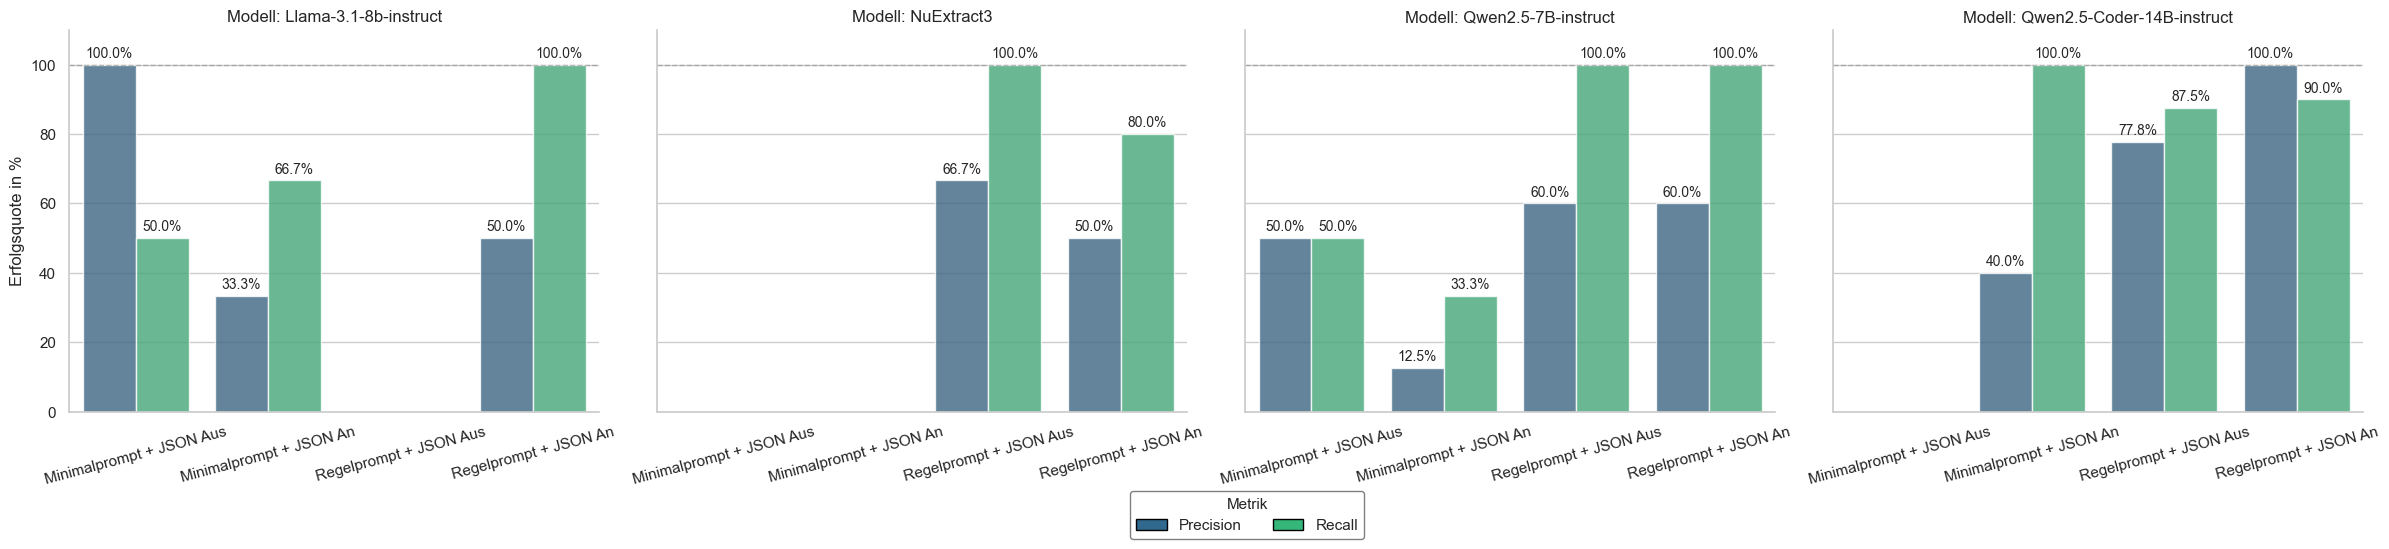

In [46]:
# ==========================================
# 2. Setup-Namen kombinieren & Bereinigen
# ==========================================
# Wir erstellen eine neue Spalte, die Prompt und Zwang kombiniert (z.B. "Regel + JSON An")
df['Setup'] = df['Strategie'] + " + JSON " + df['JSON_Schema']

# Wir filtern wieder alles raus, was technisch kaputt ist
df_bereinigt = df[(df['Parsbar_1_0'] == 1) & (df['Schema_OK_1_0'] == 1)].copy()

# ==========================================
# 3. Precision und Recall pro Modell UND Setup berechnen
# ==========================================
# Wir gruppieren jetzt nach Modell UND Setup gleichzeitig
gruppiert = df_bereinigt.groupby(['Modell', 'Setup', 'Confusion_Matrix']).size().unstack(fill_value=0).reset_index()

# Sicherstellen, dass TP, FP, FN existieren
for col in ['TP', 'FP', 'FN']:
    if col not in gruppiert.columns:
        gruppiert[col] = 0

# Metriken berechnen
gruppiert['Precision'] = (gruppiert['TP'] / (gruppiert['TP'] + gruppiert['FP']) * 100).fillna(0)
gruppiert['Recall'] = (gruppiert['TP'] / (gruppiert['TP'] + gruppiert['FN']) * 100).fillna(0)

# ==========================================
# 4. Vorbereitung für Seaborn (Melt)
# ==========================================
df_melted = gruppiert.melt(
    id_vars=['Modell', 'Setup'], 
    value_vars=['Precision', 'Recall'], 
    var_name='Metrik', 
    value_name='Prozent'
)

# Wir sortieren die Setups, damit sie in einer logischen Reihenfolge angezeigt werden
reihenfolge = ['Minimal + JSON An', 'Regel + JSON Aus', 'Regel + JSON An']
df_melted = df_melted[df_melted['Setup'].isin(reihenfolge)]

# ==========================================
# 5. Visualisierung: Setup-Vergleich pro Modell
# ==========================================
# catplot erstellt automatisch für jedes Modell ein eigenes Diagramm (col="modell")
reihenfolge = [
    'Minimalprompt + JSON Aus',
    'Minimalprompt + JSON An',
    'Regelprompt + JSON Aus',
    'Regelprompt + JSON An'
 ]

df_melted = gruppiert.melt(
    id_vars=['Modell', 'Setup'],
    value_vars=['Precision', 'Recall'],
    var_name='Metrik',
    value_name='Prozent'
)

df_melted = df_melted[df_melted['Setup'].isin(reihenfolge)]

g = sns.catplot(
    data=df_melted,
    x='Setup',
    y='Prozent',
    hue='Metrik',
    col='Modell',
    kind='bar',
    palette="viridis",
    alpha=.8,
    order=reihenfolge,
    
    height=5,
    aspect=1.2
)

# Y-Achse auf 0-110% fixieren
for ax in g.axes.flat:
    ax.set_ylim(0, 110)
    ax.axhline(100, color='grey', linestyle='--', linewidth=1, alpha=0.5)
    
    # Optional: X-Achsen-Texte leicht drehen, falls sie zu lang sind
    ax.tick_params(axis='x', rotation=15)

    # Prozentzahlen über die Balken schreiben
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            ax.annotate(f'{height:.1f}%', 
                        (p.get_x() + p.get_width() / 2., height), 
                        ha='center', va='bottom', 
                        fontsize=10, xytext=(0, 3), 
                        textcoords='offset points')

# Titel und Achsen anpassen
g.set_axis_labels("", "Erfolgsquote in %")
g.set_titles("Modell: {col_name}")

# Legende explizit relativ zur gesamten Figure zentrieren und kontrastreich gestalten
from matplotlib.patches import Patch
if g._legend is not None:
    g._legend.remove()
farben = sns.color_palette("viridis", 2)
handles = [
    Patch(facecolor=farben[0], edgecolor='black', label='Precision'),
    Patch(facecolor=farben[1], edgecolor='black', label='Recall')
 ]
g.fig.legend(
    handles=handles,
    title='Metrik',
    loc='lower center',
    bbox_to_anchor=(0.5, -0.11),
    ncol=2,
    frameon=True,
    facecolor='white',
    edgecolor='black',
    framealpha=0.5,
    title_fontsize=11
 )
g.fig.subplots_adjust(bottom=0.16)

# Als PDF speichern
plt.savefig("Strategie_auf_inhaltliche_Qualität.pdf", format="pdf", bbox_inches="tight")

plt.show()

### Inhaltliche Genauigkeit auf den Labels

(Nur korrekte Label-Erkennungen / TPs)

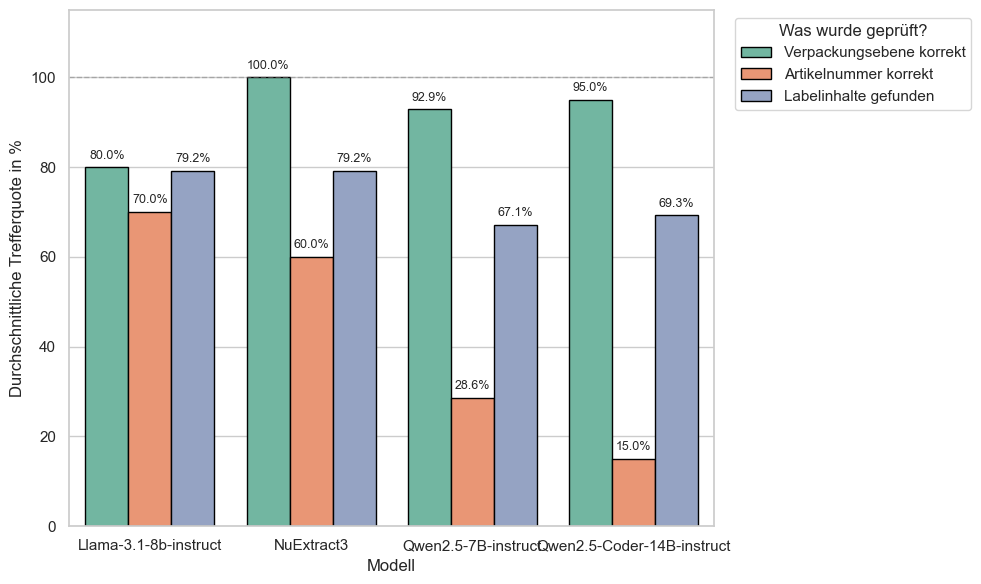

In [51]:
# ==========================================
# 2. Filtern: NUR True Positives (TP) zulassen
# ==========================================
# Wir werten Details nur aus, wenn überhaupt korrekterweise ein Label erkannt wurde
df_tp = df[df['Confusion_Matrix'] == 'TP'].copy()

# ==========================================
# 3. Durchschnittswerte pro Modell berechnen
# ==========================================
# Gruppieren nach Modell und den Mittelwert der 3 Spalten berechnen
df_mean = df_tp.groupby('Modell')[
    ['Verpackungsebene_korrekt?_1_0', 'Artikelnummer_korrekt?_1_0', 'Labelinhalte_gefunden_%']
].mean().reset_index()

# Die 1/0-Spalten in echte Prozentwerte (0-100) umwandeln
df_mean['Verpackungsebene_korrekt?_1_0'] *= 100
df_mean['Artikelnummer_korrekt?_1_0'] *= 100
df_mean['Labelinhalte_gefunden_%'] *= 100

# Spalten umbenennen, damit sie im Diagramm schön aussehen
df_mean.rename(columns={
    'Verpackungsebene_korrekt?_1_0': 'Verpackungsebene korrekt',
    'Artikelnummer_korrekt?_1_0': 'Artikelnummer korrekt',
    'Labelinhalte_gefunden_%': 'Labelinhalte gefunden'
}, inplace=True)

# ==========================================
# 4. Vorbereitung für Seaborn (Melt)
# ==========================================
df_melted = df_mean.melt(
    id_vars='Modell', 
    var_name='Detail-Metrik', 
    value_name='Prozent'
)

# ==========================================
# 5. Visualisierung: Detail-Genauigkeit pro Modell
# ==========================================
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=df_melted, 
    x='Modell', 
    y='Prozent', 
    hue='Detail-Metrik', 
    palette='Set2', # Ein Farbschema, das gut für 3 Kategorien funktioniert
    edgecolor="black"
)

# Y-Achse formatieren (Platz für Beschriftung lassen)
plt.ylim(0, 115)
plt.axhline(100, color='grey', linestyle='--', linewidth=1, alpha=0.5)

# Titel und Achsen
# plt.title('Detail-Genauigkeit der Extraktion', fontsize=14, pad=15)
plt.xlabel('Modell', fontsize=12)
plt.ylabel('Durchschnittliche Trefferquote in %', fontsize=12)

# Prozentzahlen über die Balken schreiben
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.1f}%', 
                    (p.get_x() + p.get_width() / 2., height), 
                    ha='center', va='bottom',
                    fontsize=9, xytext=(0, 4), 
                    textcoords='offset points')

# Legende platzieren
plt.legend(title='Was wurde geprüft?', bbox_to_anchor=(1.02, 1), loc='upper left')

# Als PDF speichern
plt.savefig("Detail_Genauigkeit.pdf", format="pdf", bbox_inches="tight")

plt.tight_layout()
plt.show()

### Laufzeitunterschiede


Wenn wir uns nur auf die **„richtigen“ Fälle (True Positives)** konzentrieren, die zudem **fehlerfrei formatiert** sind (Parsbar = 1, Schema = 1), eliminieren wir alle Störfaktoren. Der Output (die generierten Tokens) ist in diesen Fällen inhaltlich annähernd identisch.

Dadurch wird der Laufzeit-Vergleich extrem sauber: Wir messen nicht mehr, ob ein Modell schneller war, *weil es weniger geschrieben hat*, sondern wir messen die reine Effizienz des Modells bei exakt der gleichen Zielvorgabe.

#### Was wir aus diesen Daten lernen:

1. **Massiver Geschwindigkeitsboost:** Bei ausnahmslos **jedem** Modell führt das aktivierte JSON Schema zu einer deutlich schnelleren Laufzeit. Besonders beim größten Modell (*Qwen2.5-Coder-14B*) ist der Unterschied gewaltig: Es verzehnfacht seine Geschwindigkeit nahezu!
2. **Warum ist das Schema so viel schneller?**
Ohne den Zwang berechnet das Modell bei jedem einzelnen Token Wahrscheinlichkeiten für das gesamte Vokabular. Es "überlegt", wie es den Satz anfangen soll, ob es einen Einleitungstext schreibt oder welche Klammer die beste ist.
**Mit JSON Schema (Constrained Decoding)** wird das Modell technisch in einen Tunnel gezwungen. Alle Tokens, die nicht ins Schema passen, werden im Hintergrund hart blockiert. Das Modell muss diese Pfade gar nicht erst berechnen oder ausgeben. Es kommt sofort zur Sache, was die Berechnungszeit drastisch senkt.
3. **Der Sweetspot aus Performance und Qualität:** Du hast jetzt den Daten-Beweis, dass das JSON-Schema nicht nur gut ist, um Formatfehler zu vermeiden (siehe vorige Auswertungen), sondern dass es auch der ultimative Hebel ist, um **Kosten und Laufzeiten im Live-Betrieb massiv zu senken**.

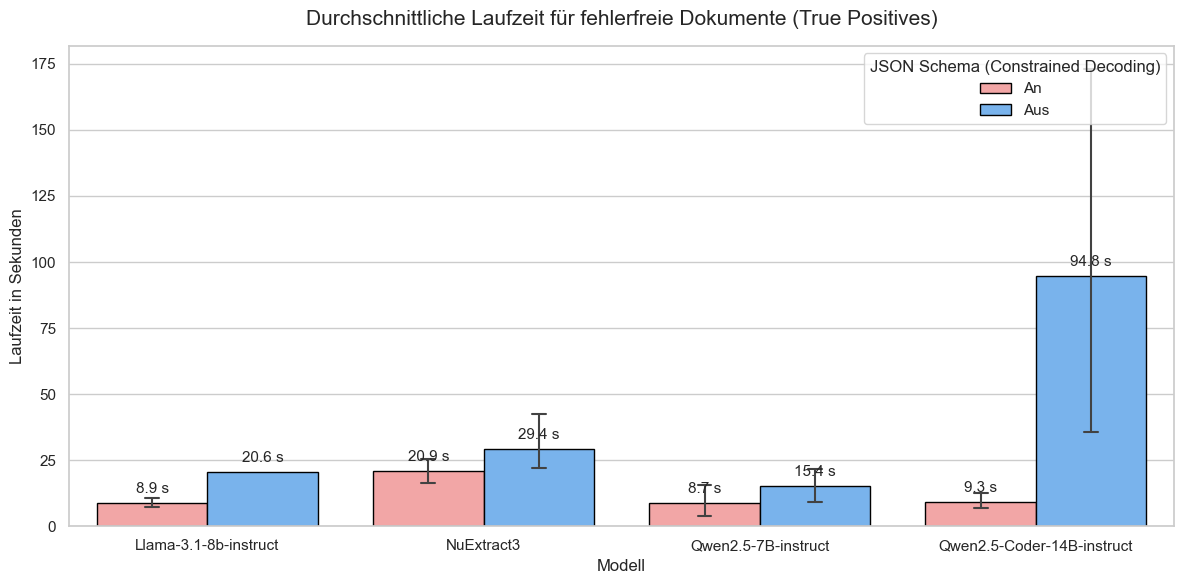

In [41]:
df['Laufzeit_in_s'] = df['Laufzeit_in_s'].apply(lambda x: float(str(x).replace(',', '.')) if pd.notnull(x) else x)

# 2. Strikt filtern (Die "richtigen" und formstabilen Fälle)
df_clean = df[(df['Parsbar_1_0'] == 1) & 
              (df['Schema_OK_1_0'] == 1) & 
              (df['Confusion_Matrix'] == 'TP')]

# 3. Visualisierung
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=df_clean,
    x='Modell',
    y='Laufzeit_in_s',
    hue='JSON_Schema',
    palette=['#ff9999', '#66b3ff'], # Rot/Blau für Aus/An
    edgecolor='black',
    capsize=0.1,  # Zeigt kleine Fehlerbalken für die Streuung an
    err_kws={'linewidth': 1.5}
)

# Layout optimieren
plt.title('Durchschnittliche Laufzeit für fehlerfreie Dokumente (True Positives)', fontsize=15, pad=15)
plt.ylabel('Laufzeit in Sekunden', fontsize=12)
plt.xlabel('Modell', fontsize=12)
plt.legend(title='JSON Schema (Constrained Decoding)', loc='upper right')

# Zahlen direkt auf die Balken schreiben
for p in ax.patches:
    height = p.get_height()
    if height > 0 and pd.notna(height):
        ax.annotate(f'{height:.1f} s', 
                    (p.get_x() + p.get_width() / 2., height), 
                    ha='center', va='bottom', 
                    fontsize=11, xytext=(0, 5), 
                    textcoords='offset points')

plt.tight_layout()
plt.show()

/var/folders/30/63lkbzns3j12bfmt1pfdtl540000gn/T/ipykernel_48916/4273340545.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/var/folders/30/63lkbzns3j12bfmt1pfdtl540000gn/T/ipykernel_48916/4273340545.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


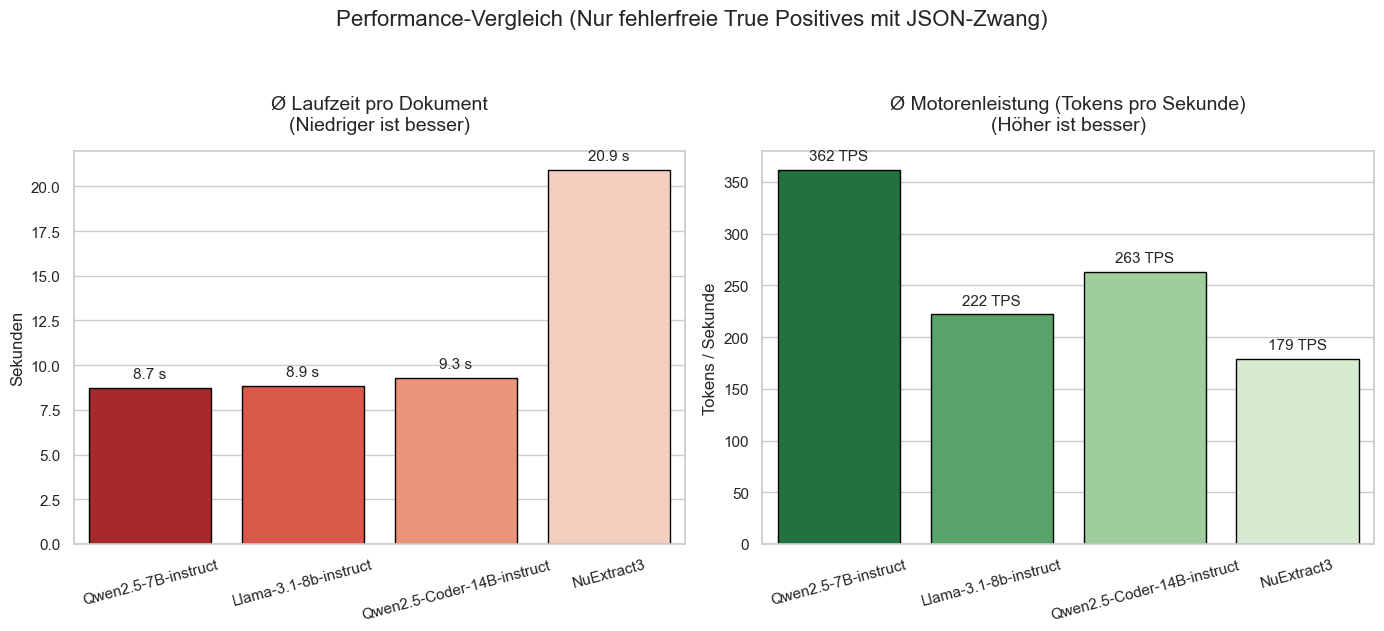

In [42]:
# ==========================================
# 1. Laufzeit bereinigen
# ==========================================
df['Laufzeit_in_s'] = df['Laufzeit_in_s'].apply(
    lambda x: float(str(x).replace(',', '.')) if pd.notnull(x) else x
)

# ==========================================
# 2. Fairen Vergleichs-Datensatz erstellen
# ==========================================
# Wir nehmen nur formstabile TPs, bei denen der JSON-Zwang AKTIV war.
# Das garantiert, dass die Modelle unter exakt gleichen Bedingungen liefen.
df_fair = df[(df['Parsbar_1_0'] == 1) & 
             (df['Schema_OK_1_0'] == 1) & 
             (df['Confusion_Matrix'] == 'TP') &
             (df['JSON_Schema'] == 'An')].copy()

# TPS (Tokens per Second) berechnen
df_fair['Tokens_per_Second'] = df_fair['Total_tokens'] / df_fair['Laufzeit_in_s']

# Durchschnittswerte pro Modell berechnen
df_agg = df_fair.groupby('Modell')[['Laufzeit_in_s', 'Tokens_per_Second']].mean().reset_index()
# Wir sortieren nach Laufzeit (schnellstes Modell zuerst)
df_agg = df_agg.sort_values(by='Laufzeit_in_s')

# ==========================================
# 3. Visualisierung (2 Diagramme nebeneinander)
# ==========================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- Linkes Diagramm: Laufzeit (Niedriger ist besser) ---
sns.barplot(
    data=df_agg, 
    x='Modell', 
    y='Laufzeit_in_s', 
    palette='Reds_r', # Rot = Zeit/Warten
    edgecolor='black',
    ax=axes[0]
)
axes[0].set_title('Ø Laufzeit pro Dokument\n(Niedriger ist besser)', fontsize=14, pad=15)
axes[0].set_ylabel('Sekunden', fontsize=12)
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=15)

# Werte auf die Balken schreiben
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():.1f} s', 
                     (p.get_x() + p.get_width() / 2., p.get_height()), 
                     ha='center', va='bottom', fontsize=11, xytext=(0, 5), textcoords='offset points')


# --- Rechtes Diagramm: Tokens pro Sekunde (Höher ist besser) ---
sns.barplot(
    data=df_agg, 
    x='Modell', 
    y='Tokens_per_Second', 
    palette='Greens_r', # Grün = Geschwindigkeit/Leistung
    edgecolor='black',
    ax=axes[1]
)
axes[1].set_title('Ø Motorenleistung (Tokens pro Sekunde)\n(Höher ist besser)', fontsize=14, pad=15)
axes[1].set_ylabel('Tokens / Sekunde', fontsize=12)
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=15)

# Werte auf die Balken schreiben
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.0f} TPS', 
                     (p.get_x() + p.get_width() / 2., p.get_height()), 
                     ha='center', va='bottom', fontsize=11, xytext=(0, 5), textcoords='offset points')

# Layout optimieren
plt.suptitle('Performance-Vergleich (Nur fehlerfreie True Positives mit JSON-Zwang)', fontsize=16, y=1.05)
plt.tight_layout()
plt.show()

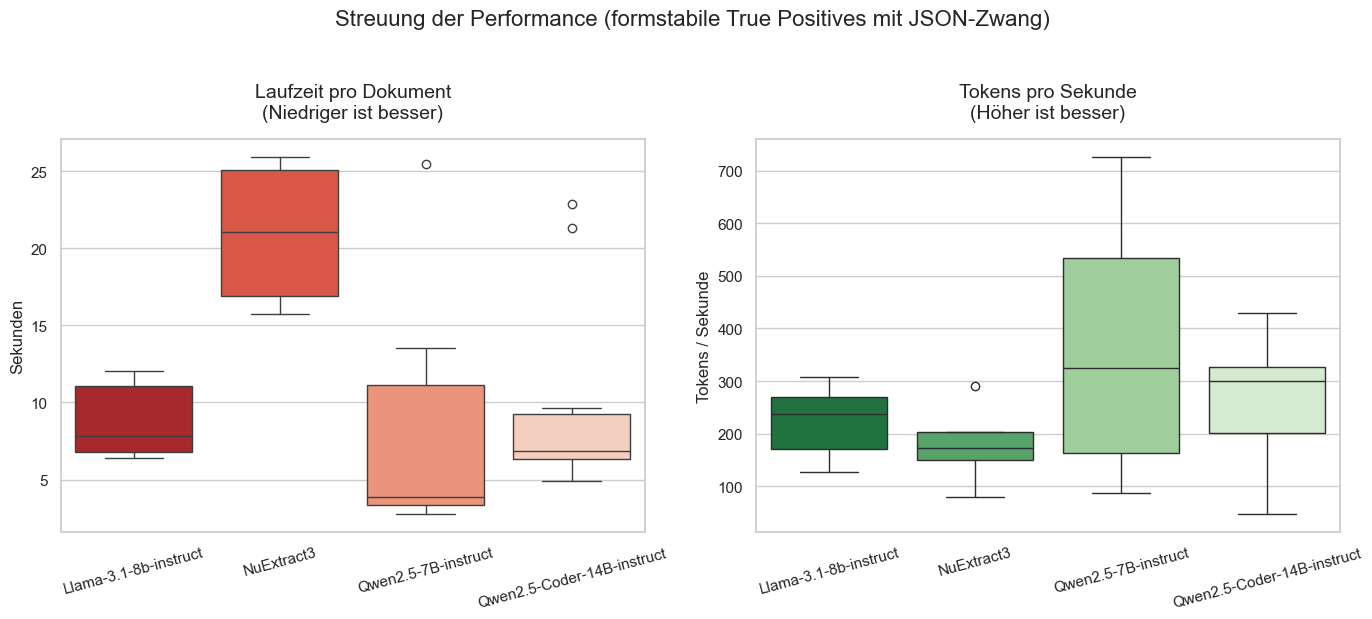

In [43]:
# ==========================================
# Boxplots: Laufzeit und Tokens pro Sekunde
# ==========================================
# Verteilungen der formstabilen True Positives mit aktiviertem JSON-Zwang
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- Linker Boxplot: Laufzeit (Niedriger ist besser) ---
sns.boxplot(
    data=df_fair,
    x='Modell',
    y='Laufzeit_in_s',
    hue='Modell',
    palette='Reds_r',
    legend=False,
    ax=axes[0]
 )
axes[0].set_title('Laufzeit pro Dokument\n(Niedriger ist besser)', fontsize=14, pad=15)
axes[0].set_ylabel('Sekunden', fontsize=12)
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=15)

# --- Rechter Boxplot: Tokens pro Sekunde (Höher ist besser) ---
sns.boxplot(
    data=df_fair,
    x='Modell',
    y='Tokens_per_Second',
    hue='Modell',
    palette='Greens_r',
    legend=False,
    ax=axes[1]
 )
axes[1].set_title('Tokens pro Sekunde\n(Höher ist besser)', fontsize=14, pad=15)
axes[1].set_ylabel('Tokens / Sekunde', fontsize=12)
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=15)

plt.suptitle('Streuung der Performance (formstabile True Positives mit JSON-Zwang)', fontsize=16, y=1.03)
plt.tight_layout()
plt.savefig("Performance_Boxplots.pdf", format="pdf", bbox_inches="tight")
plt.show()

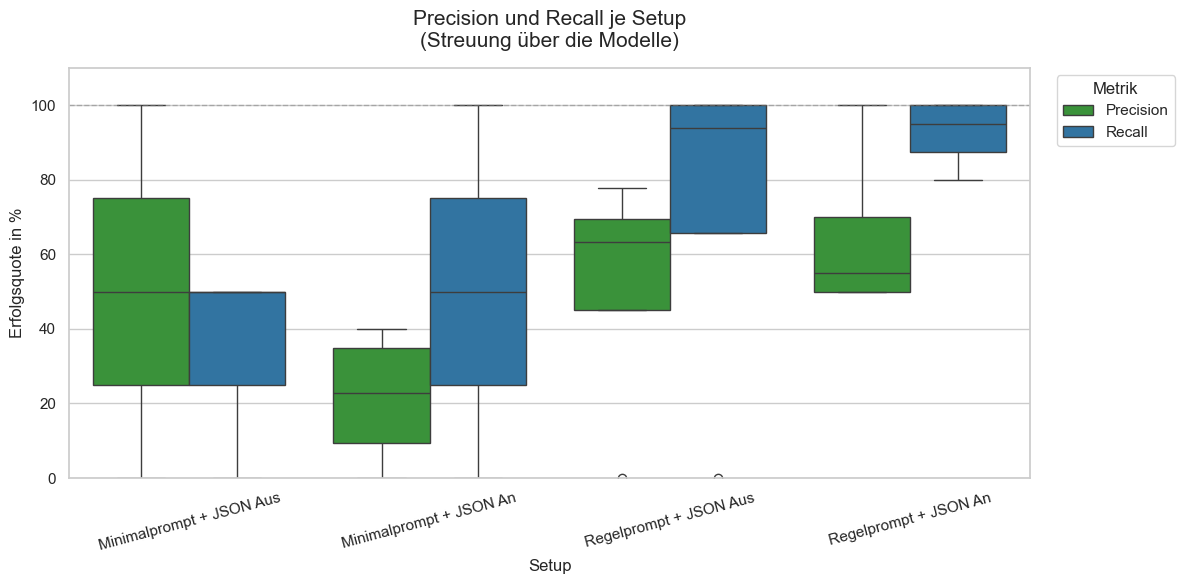

In [44]:
# ==========================================
# Boxplot: Precision und Recall je Setup
# ==========================================

# Daten wie im markierten Balkendiagramm aggregieren
df_bereinigt_boxplot = df[(df['Parsbar_1_0'] == 1) & (df['Schema_OK_1_0'] == 1)].copy()
df_bereinigt_boxplot['Setup'] = (
    df_bereinigt_boxplot['Strategie'] + " + JSON " + df_bereinigt_boxplot['JSON_Schema']
 )

gruppiert_boxplot = (
    df_bereinigt_boxplot
    .groupby(['Modell', 'Setup', 'Confusion_Matrix'])
    .size()
    .unstack(fill_value=0)
    .reset_index()
 )

for col in ['TP', 'FP', 'FN']:
    if col not in gruppiert_boxplot.columns:
        gruppiert_boxplot[col] = 0

gruppiert_boxplot['Precision'] = (
    gruppiert_boxplot['TP'] /
    (gruppiert_boxplot['TP'] + gruppiert_boxplot['FP']) * 100
 ).fillna(0)
gruppiert_boxplot['Recall'] = (
    gruppiert_boxplot['TP'] /
    (gruppiert_boxplot['TP'] + gruppiert_boxplot['FN']) * 100
 ).fillna(0)

df_melted_boxplot = gruppiert_boxplot.melt(
    id_vars=['Modell', 'Setup'],
    value_vars=['Precision', 'Recall'],
    var_name='Metrik',
    value_name='Prozent'
)

reihenfolge = [
    'Minimalprompt + JSON Aus',
    'Minimalprompt + JSON An',
    'Regelprompt + JSON Aus',
    'Regelprompt + JSON An'
 ]
df_melted_boxplot = df_melted_boxplot[
    df_melted_boxplot['Setup'].isin(reihenfolge)
 ]

# Boxplots zeigen die Streuung der Modellwerte je Setup
plt.figure(figsize=(12, 6))
ax = sns.boxplot(
    data=df_melted_boxplot,
    x='Setup',
    y='Prozent',
    hue='Metrik',
    order=reihenfolge,
    palette=['#2ca02c', '#1f77b4']
 )

plt.ylim(0, 110)
plt.axhline(100, color='grey', linestyle='--', linewidth=1, alpha=0.5)
plt.title('Precision und Recall je Setup\n(Streuung über die Modelle)', fontsize=15, pad=15)
plt.xlabel('Setup', fontsize=12)
plt.ylabel('Erfolgsquote in %', fontsize=12)
plt.xticks(rotation=15)
plt.legend(title='Metrik', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.savefig("Strategie_Boxplots.pdf", format="pdf", bbox_inches="tight")
plt.show()

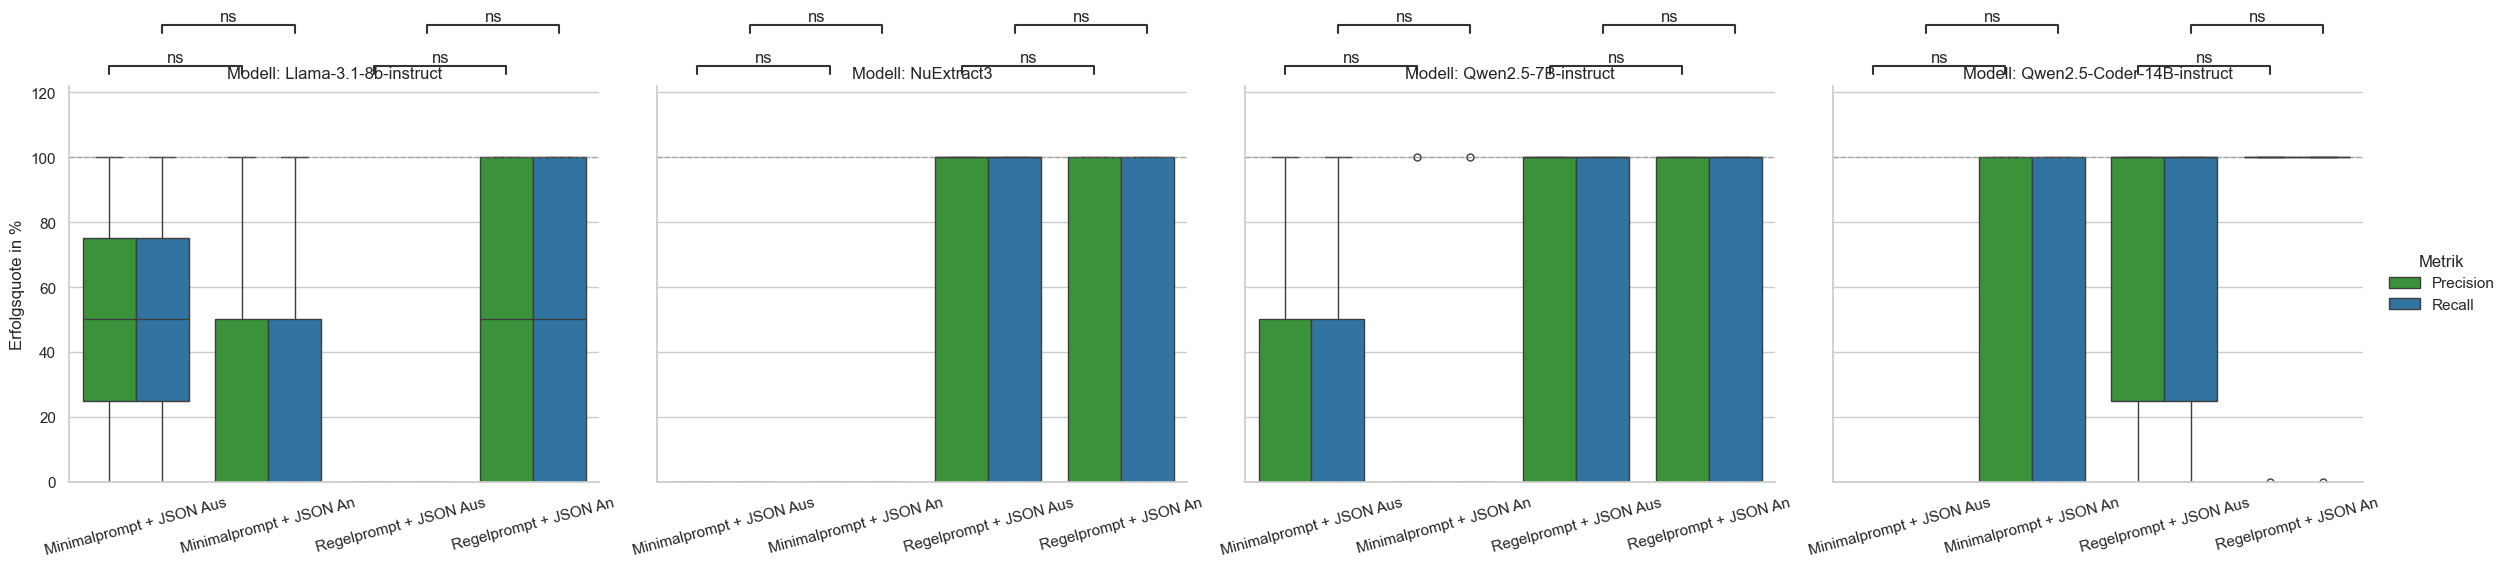

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns
from statannotations.Annotator import Annotator

# ==========================================
# 2. Setup-Namen kombinieren & Bereinigen
# ==========================================
df['Setup'] = df['Strategie'] + " + JSON " + df['JSON_Schema']
df_bereinigt = df[(df['Parsbar_1_0'] == 1) & (df['Schema_OK_1_0'] == 1)].copy()

# ==========================================
# 3. Precision und Recall pro Modell, Setup UND Testlauf berechnen
# ==========================================
# HINWEIS: 'Run' unterscheidet deine einzelnen Testläufe/Iterationen für die Verteilung
gruppiert = df_bereinigt.groupby(['Modell', 'Setup', 'Run_ID', 'Confusion_Matrix']).size().unstack(fill_value=0).reset_index()

# Sicherstellen, dass TP, FP, FN existieren
for col in ['TP', 'FP', 'FN']:
    if col not in gruppiert.columns:
        gruppiert[col] = 0

# Metriken pro Durchlauf berechnen
gruppiert['Precision'] = (gruppiert['TP'] / (gruppiert['TP'] + gruppiert['FP']) * 100).fillna(0)
gruppiert['Recall'] = (gruppiert['TP'] / (gruppiert['TP'] + gruppiert['FN']) * 100).fillna(0)

# ==========================================
# 4. Vorbereitung für Seaborn (Melt)
# ==========================================
reihenfolge = [
    'Minimalprompt + JSON Aus',
    'Minimalprompt + JSON An',
    'Regelprompt + JSON Aus',
    'Regelprompt + JSON An'
 ]

df_melted = gruppiert.melt(
    id_vars=['Modell', 'Setup', 'Run_ID'], 
    value_vars=['Precision', 'Recall'], 
    var_name='Metrik', 
    value_name='Prozent'
)

df_melted = df_melted[df_melted['Setup'].isin(reihenfolge)]

# ==========================================
# 5. Visualisierung: Boxplots mit Signifikanzen
# ==========================================
g = sns.catplot(
    data=df_melted,
    x='Setup',
    y='Prozent',
    hue='Metrik',
    col='Modell',
    kind='box',
    palette=['#2ca02c', '#1f77b4'],
    order=reihenfolge,
    height=5,
    aspect=1.2
)

# Zu vergleichende Paare definieren (Da 'hue=Metrik' genutzt wird, geben wir Tupel aus Setup und Metrik an)
box_pairs = [
    (('Minimalprompt + JSON Aus', 'Precision'), ('Minimalprompt + JSON An', 'Precision')),
    (('Regelprompt + JSON Aus', 'Precision'), ('Regelprompt + JSON An', 'Precision')),
    (('Minimalprompt + JSON Aus', 'Recall'), ('Minimalprompt + JSON An', 'Recall')),
    (('Regelprompt + JSON Aus', 'Recall'), ('Regelprompt + JSON An', 'Recall'))
]

# Für jedes Modell (Achse) die p-Werte berechnen und Klammern einzeichnen
for ax in g.axes.flat:
    # Y-Achse nach oben erweitern (bis 120%), damit die Klammern für p-Werte Platz haben
    ax.set_ylim(0, 122)
    ax.axhline(100, color='grey', linestyle='--', linewidth=1, alpha=0.5)
    ax.tick_params(axis='x', rotation=15)

    # Annotator für statistische Tests initialisieren
    annotator = Annotator(
        ax, 
        box_pairs, 
        data=df_melted, 
        x='Setup', 
        y='Prozent', 
        hue='Metrik', 
        order=reihenfolge
    )
    
    # Test konfigurieren ('Mann-Whitney' oder 't-test_ind')
    annotator.configure(
        test='Mann-Whitney',   # Empfohlen für nicht-normalverteilte Metriken (Prozentwerte)
        text_format='star',    # 'star' für (*, **, ***) oder 'full' für exakte p-Werte (z.B. p = 0.034)
        loc='outside',         # Klammern oberhalb der Boxen platzieren
        verbose=0
    )
    annotator.apply_and_annotate()

# Titel und Achsen anpassen
g.set_axis_labels("", "Erfolgsquote in %")
g.set_titles("Modell: {col_name}")

# Als PDF speichern
plt.savefig("Strategie_auf_Qualität_mit_Signifikanzen.pdf", format="pdf", bbox_inches="tight")

plt.show()